# 04 — Model Evaluation

Comprehensive evaluation on the held-out test set:
- Quadratic Weighted Kappa (primary clinical metric)
- Per-class Precision / Recall / F1
- Confusion matrices (absolute + normalised)
- Per-class ROC curves with AUC
- Misclassified image gallery

In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
from src.data_manager import ensure_dataset

ensure_dataset()
config.ensure_dirs()

print(f"Images dir: {config.IMAGES_DIR} (exists: {os.path.isdir(config.IMAGES_DIR)})")
print(f"Outputs dir: {config.OUTPUTS_DIR}")

/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped (exists: True)
Outputs dir: /teamspace/studios/this_studio/diabetic_retinopathy/outputs


In [2]:
import pandas as pd
import torch

from src import config
from src.augmentations import get_valid_transforms
from src.dataset import DRDataset
from src.evaluate import full_evaluation, plot_training_curves
from src.model import build_model
from src.utils import get_device, seed_everything

seed_everything()
device = get_device()

Using GPU: NVIDIA H100 80GB HBM3 (84.9 GB)


## 1. Load Test Data and Model

In [3]:
# Load the saved splits from training (stored on Drive for persistence)
test_df = pd.read_csv(os.path.join(config.OUTPUTS_DIR, 'test_split.csv'))
print(f'Test set: {len(test_df):,} images')
print('Class distribution:')
print(test_df['level'].value_counts().sort_index())

Test set: 5,268 images
Class distribution:
level
0    3872
1     363
2     795
3     134
4     104
Name: count, dtype: int64


In [4]:
# Build DataLoader
valid_transforms = get_valid_transforms()
test_dataset = DRDataset(
    test_df,
    images_dir=config.IMAGES_DIR,
    transform=valid_transforms,
    preprocessing=True,
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config.PHASE1_BATCH_SIZE,
    shuffle=False,
    num_workers=config.NUM_WORKERS,
    pin_memory=config.PIN_MEMORY,
)

print(f'Test batches: {len(test_loader)}')

Test batches: 165


In [5]:
# Load trained model
model = build_model(pretrained=False)

ckpt_path = os.path.join(config.CHECKPOINTS_DIR, 'best_model_phase3.pth')
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model = model.to(device)
model.eval()

print(f'Loaded checkpoint: {ckpt_path}')
print(f'  Epoch: {ckpt["epoch"] + 1}')
print(f'  Val QWK: {ckpt["metrics"]["kappa"]:.4f}')
print(f'  Val Acc: {ckpt["metrics"]["acc"]:.4f}')

Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase3.pth
  Epoch: 19
  Val QWK: 0.5722
  Val Acc: 0.4329


## 2. Full Evaluation

EVALUATION RESULTS

Quadratic Weighted Kappa : 0.5773
Accuracy                : 0.4201
Weighted ROC-AUC (OvR)  : 0.8211

                  precision    recall  f1-score   support

           No_DR     0.9162    0.4153    0.5715      3872
            Mild     0.0953    0.6804    0.1671       363
        Moderate     0.5544    0.2629    0.3567       795
          Severe     0.2467    0.5597    0.3425       134
Proliferative_DR     0.3096    0.7115    0.4315       104

        accuracy                         0.4201      5268
       macro avg     0.4244    0.5260    0.3739      5268
    weighted avg     0.7761    0.4201    0.5026      5268



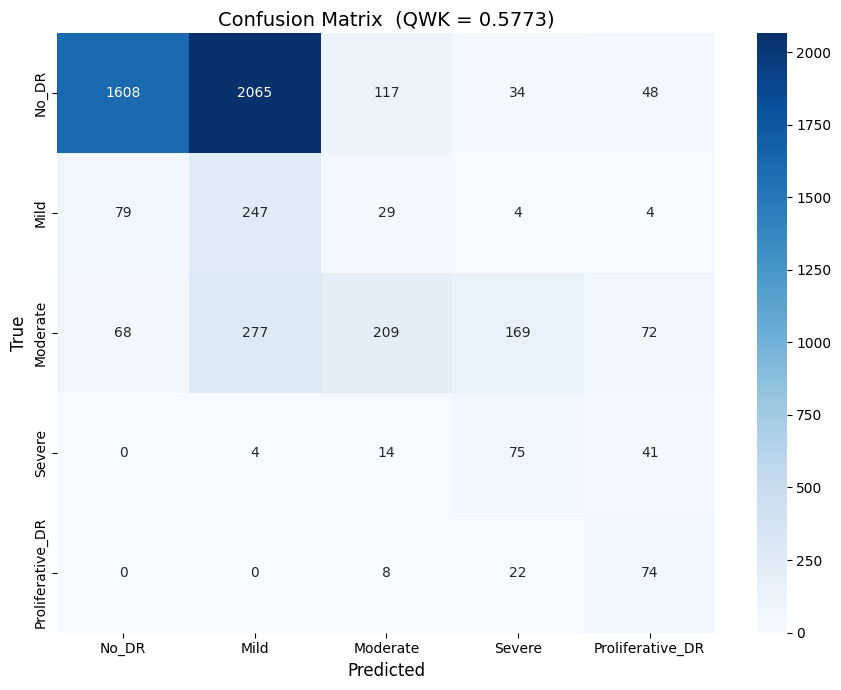

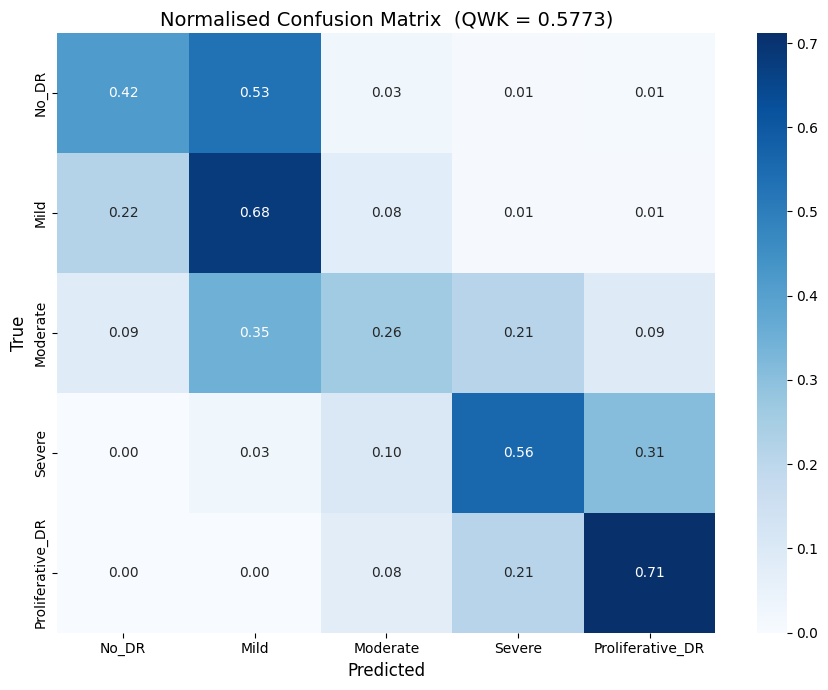

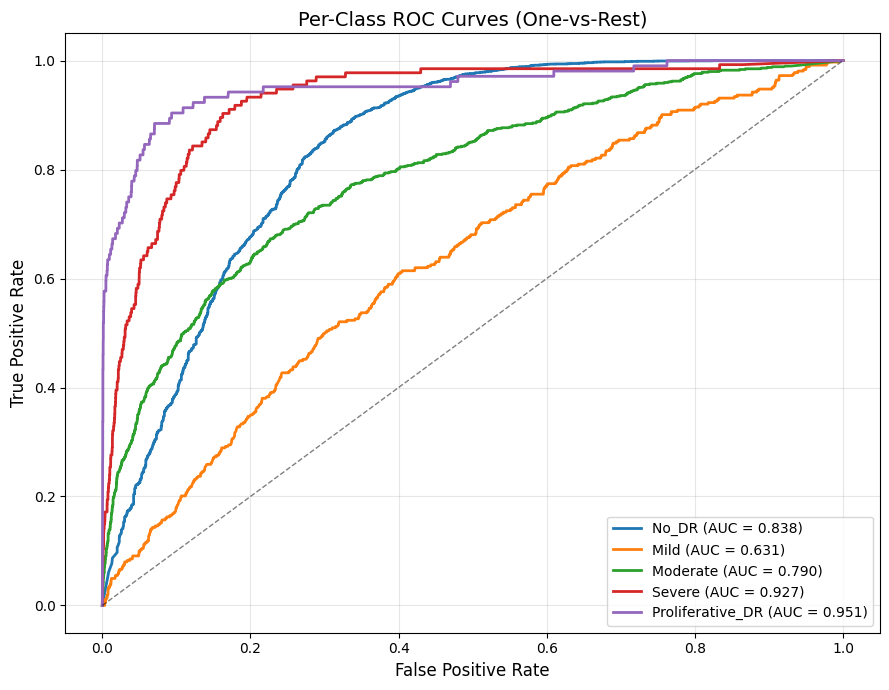

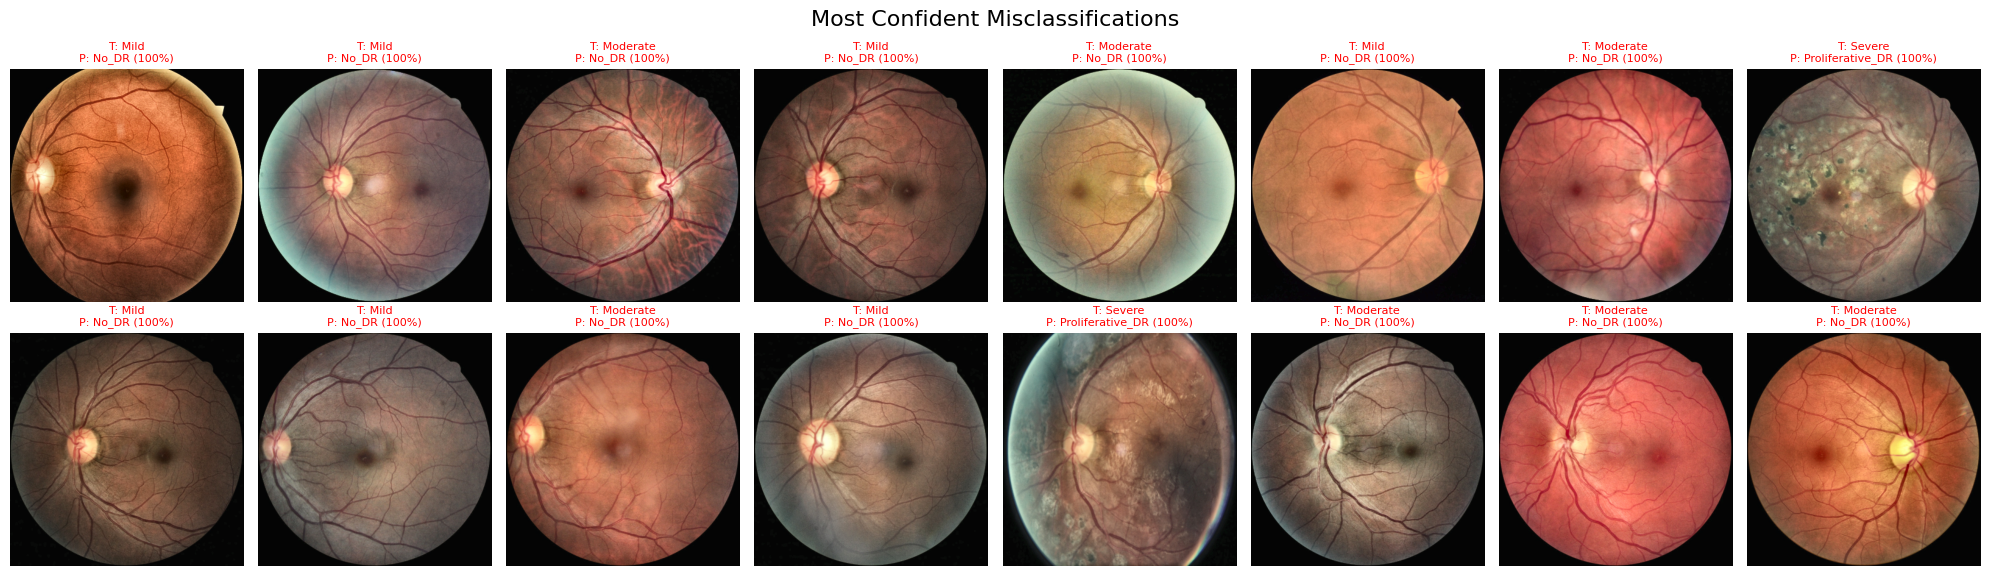

In [6]:
metrics = full_evaluation(
    model=model,
    test_loader=test_loader,
    device=device,
    test_dataset=test_dataset,
    save_dir=config.FIGURES_DIR,
)

## 3. Training Curves

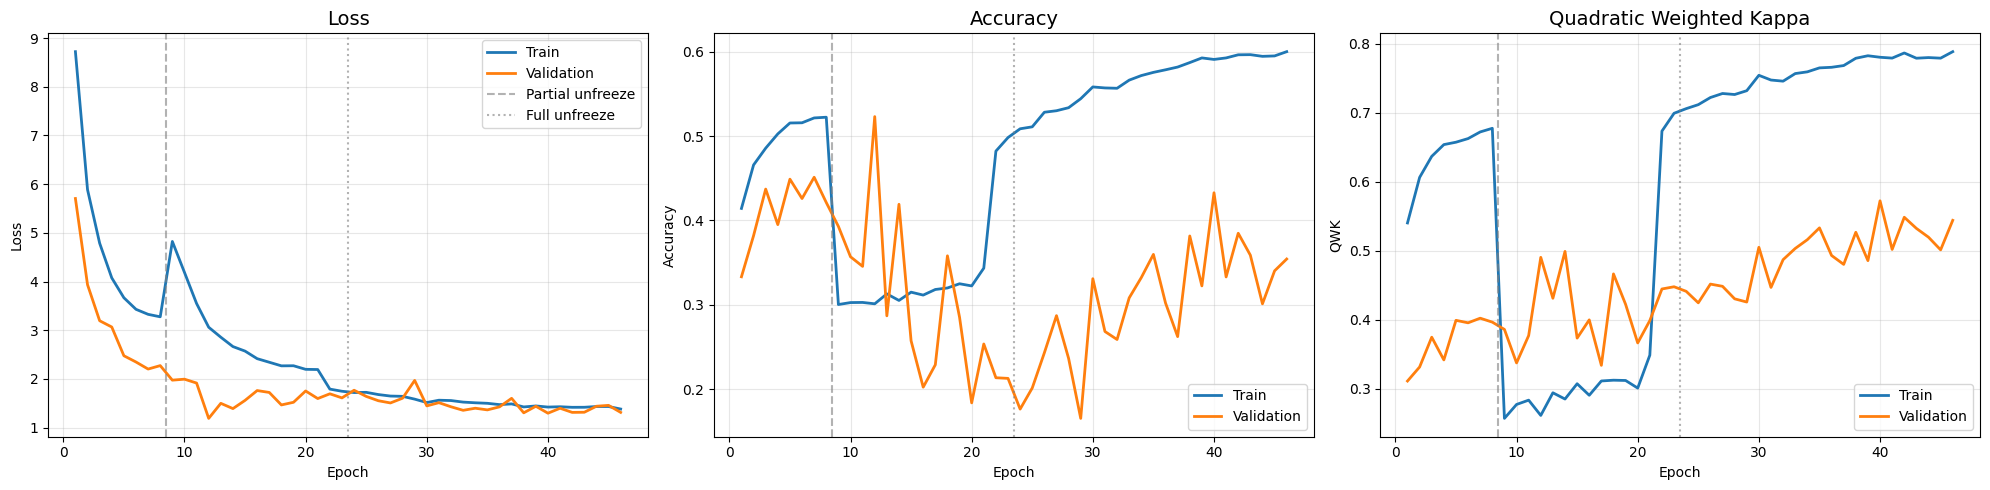

In [7]:
import json

history_path = os.path.join(config.LOGS_DIR, 'training_history.json')
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    plot_training_curves(history, save_path=os.path.join(config.FIGURES_DIR, 'training_curves.png'))
else:
    print('No training history found. Run notebook 03 first.')

## 4. Single-Image Inference

Image: 40551_right  |  True label: No_DR


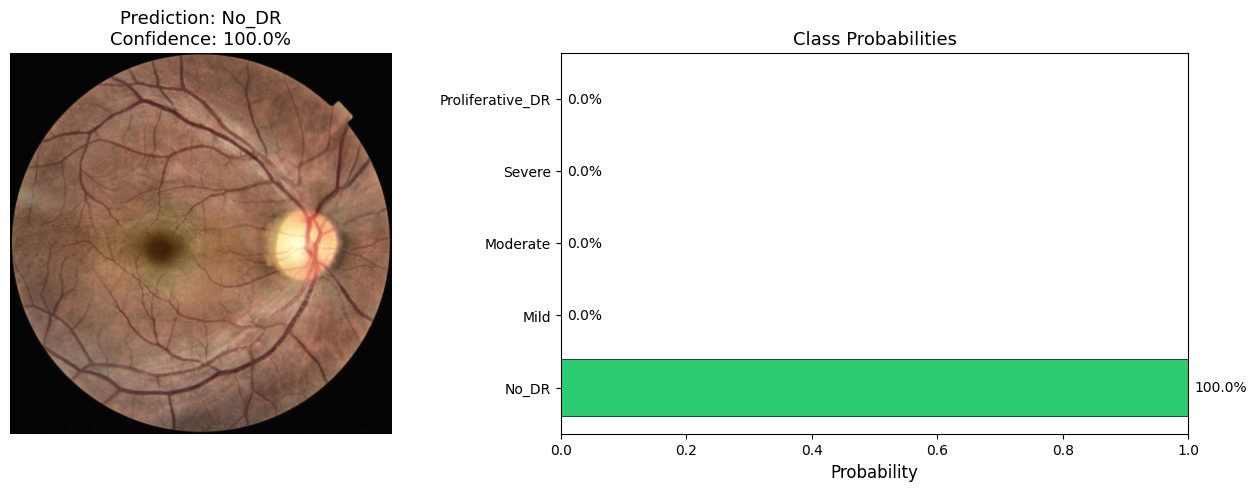


  0 - No Diabetic Retinopathy
  Confidence: 100.0%


In [8]:
from src.evaluate import predict_single_image


def find_image(images_dir, image_id):
    """Try common extensions and return the file path, or None."""
    for ext in ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG'):
        p = os.path.join(images_dir, image_id + ext)
        if os.path.isfile(p):
            return p
    return None

# Pick a random test image
sample_row = test_df.sample(1, random_state=config.SEED).iloc[0]
sample_path = find_image(config.IMAGES_DIR, sample_row['image'])

if sample_path is None:
    print(f"ERROR: Could not find image for '{sample_row['image']}' in {config.IMAGES_DIR}")
else:
    print(f"Image: {sample_row['image']}  |  True label: {config.CLASS_NAMES[sample_row['level']]}")
    result = predict_single_image(
        model, sample_path, device,
        save_path=os.path.join(config.FIGURES_DIR, 'single_prediction.png'),
    )
    print(f"\n  {result['severity']}")
    print(f"  Confidence: {result['confidence']:.1%}")

## 5. Test-Time Augmentation (TTA)

TTA averages predictions across multiple geometric transforms of the same image, typically boosting accuracy by 0.5-1%.

In [9]:
from src.evaluate import compute_metrics, predict, predict_with_tta

# Standard prediction (no TTA)
y_true, y_pred_std, y_proba_std = predict(model, test_loader, device)
metrics_std = compute_metrics(y_true, y_pred_std, y_proba_std)

# TTA prediction
y_true_tta, y_pred_tta, y_proba_tta = predict_with_tta(
    model, test_df, config.IMAGES_DIR, device,
)
metrics_tta = compute_metrics(y_true_tta, y_pred_tta, y_proba_tta)

# Comparison table
import pandas as pd

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'QWK', 'ROC-AUC'],
    'Standard': [
        f"{metrics_std['accuracy']:.4f}",
        f"{metrics_std['qwk']:.4f}",
        f"{metrics_std['roc_auc_weighted']:.4f}",
    ],
    'With TTA': [
        f"{metrics_tta['accuracy']:.4f}",
        f"{metrics_tta['qwk']:.4f}",
        f"{metrics_tta['roc_auc_weighted']:.4f}",
    ],
})
print(comparison.to_string(index=False))

TTA transforms: 100%|██████████| 4/4 [00:36<00:00,  9.18s/it]

  Metric Standard With TTA
Accuracy   0.4201   0.4243
     QWK   0.5773   0.5849
 ROC-AUC   0.8211   0.8263


## 6. Summary

Key metrics to report:
- **QWK** (Quadratic Weighted Kappa): the gold standard for DR grading
- **Per-class F1**: shows how well the model handles each severity level
- **ROC-AUC**: overall discriminative ability
- TTA provides a free accuracy boost at inference time
- The confusion matrix reveals common misclassification patterns (typically adjacent grades)